# Example EODs: my model vs Denis' pipeline (2-fish and 3-fish recordings)

For each recording, 20 EODs from the **good frames** (mask QC and SLEAP both good, Denis' `good_frame`):

| outcome | n |
|---|---|
| both right | 5 |
| only mine right | 5 |
| only Denis right | 5 |
| both wrong | 5 |

Within each outcome, the 5 EODs span the distance between the emitter and the nearest other fish (mask edge to edge, the `gap_cm`
of the conductivities notebooks): one EOD at random (`default_rng(0)`) from each fifth of the good-frame distances, close to far.

- **My model**: BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, sign fixed
  (model × −1), as in `EOD_assignment_{2,3}_fish_conductivities.ipynb`. Model voltages from those notebooks' caches.
- **Denis**: his latest run (`eod_assignment_summary.csv` and the `Assigned_Data_*.pkl` next to it); his fish A/B/C are ordered by
  length.

Each figure:
- **tank**: video frame, mask of each fish, my midline, Denis' midline, SLEAP keypoints, electrodes (pair number and polarity);
- **voltages at the 10 electrode pairs**, one row per fish as the candidate emitter:
  - black: recorded, scaled to max |v| = 1 at the peak sample;
  - blue: my model for that fish (× −1, scaled to max |v| = 1) times the recorded EOD waveform;
  - orange: Denis' predicted pattern for that fish (scaled to max |v| = 1, with the sign his similarity uses) times the same waveform.

Colours: **blue = my model, orange = Denis**, everywhere.

In [1]:
import os, pickle, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, rank1_pattern

REC = {
    '3-fish': dict(
        data='data/3_fish_silent', eod_csv='Assigned_Data_3fish_2024-10-15T14_12_25.csv',
        track='elephantnose_20241015T141225_tracking_final.pkl', video='video2024-10-15T14_12_25.avi',
        electrodes='data/electrodes/electrodes_signed_px_coord_3-fish.csv',
        res='results/eod_ground_truth_3fish/conductivities',
        cache='model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
        denis_pkl='results/eod_assignment_3_fish_silent/electrodes_3-fish/Assigned_Data_3fish_2024-10-15T14_12_25.pkl',
        fish=(0, 1, 2), emitter=0, denis_map={'A': 1, 'B': 2, 'C': 0},
        fish_color={0: '#E0B000', 1: '#D45087', 2: '#2E8B57'}),
    '2-fish': dict(
        data='data/2_fish_silent', eod_csv='Data_1fish_2024-02-13T14_33_21.csv',
        track='elephantnose_20240213T143321_tracking_final.pkl', video='video2024-02-13T14_33_21.avi',
        electrodes='data/electrodes/electrodes_signed_px_coord_2-fish.csv',
        res='results/eod_ground_truth/conductivities',
        cache='model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
        denis_pkl='results/eod_assignment_2_fish_silent/electrodes_2-fish/Assigned_Data_1fish_2024-02-13T14_33_21.pkl',
        fish=(0, 1), emitter=1, denis_map={'A': 1, 'B': 0},
        fish_color={0: '#2E8B57', 1: '#D45087'}),
}
MINE = 'BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'   # column of eod_assignments.csv
DENIS = "Denis' pipeline (latest run)"
C_MINE, C_DENIS, C_REC = '#1F5FBF', '#E8710A', 'k'   # my model blue, Denis orange, recorded black
PX_PER_CM = 912 / 60                                  # Denis' pixel2cm
FS = 50000.0                                          # electrode sampling rate (Hz)
n_poles = 100
OUTCOMES = ['both right', 'only mine right', 'only Denis right', 'both wrong']
N_BINS, SEED = 5, 0
OUTLINE = [pe.withStroke(linewidth=3, foreground='k')]

In [2]:
def load_recording(name):
    '''Everything the examples need for one recording, as a dict.'''
    c = dict(REC[name], name=name)
    df = pd.read_csv(f"{c['data']}/{c['eod_csv']}")
    pat = re.compile(r'electrode_(\d+)_t(?:ime)?_([mp]?)(\d+)$')       # sample k (2-fish) or m12 ... 0 ... p12 (3-fish)
    cols = {}
    for col in df.columns:
        m = pat.match(col)
        if m: cols.setdefault(int(m[1]), []).append(((-1 if m[2] == 'm' else 1) * int(m[3]), col))
    c['trace_cols'] = {p: [col for _, col in sorted(v)] for p, v in sorted(cols.items())}
    assert len(c['trace_cols']) == 10 and len({len(v) for v in c['trace_cols'].values()}) == 1
    with open(f"{c['data']}/{c['track']}", 'rb') as f:
        trk = pickle.load(f)
    c.update(df=df, frames=trk['frames'], P=trk['shape'][0], fps=trk['fps'])
    c['pairs'] = load_electrode_pairs(c['electrodes'], c['P'])
    c['pair_ids'] = [pid for pid, _, _ in c['pairs']]
    c['assigned'] = pd.read_csv(f"{c['res']}/eod_assignments.csv", index_col='row')
    c['cache'] = pd.read_pickle(f"{c['res']}/{c['cache']}")
    c['den'] = pd.read_pickle(c['denis_pkl'])
    n = len(df)
    assert len(c['assigned']) == len(c['cache']) == len(c['den']) == n
    for t in (c['assigned'].Frame, c['cache'].frame, c['den'].Frame):
        assert (np.asarray(t) == df.Frame.to_numpy()).all()
    return c

def recorded_pair_traces(c, i):
    '''(n_pairs, n_samp) recorded voltages of EOD row i, each pair demeaned.'''
    V = np.stack([c['df'].loc[i, c['trace_cols'][p]].to_numpy(float) for p in c['pair_ids']])
    return V - np.nanmean(V, axis=1, keepdims=True)

def frame_masks(c, k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask).'''
    P = c['P']; m = np.zeros((len(c['fish']), P, P), bool)
    fr = c['frames'][k]
    for l, p, (y0, y1, x0, x1) in zip(fr['labels'], fr['masks'], fr['boxes']):
        if l in c['fish']: m[l, y0:y1, x0:x1] = mm.unpack_crop(p, (y0, y1, x0, x1))
    return m

def video_frame(c, k):
    '''Grayscale (P, P) frame k of the raw video (ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f"{k / c['fps']:.4f}", '-i', f"{c['data']}/{c['video']}", '-frames:v', '1',
                          '-f', 'rawvideo', '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(c['P'], c['P'])

def fish_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords (row, col) / (P - 1), tail -> head, of every fish; None where it fails.'''
    out = []
    for m in fm:
        try:
            mid = fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] if m.any() else None
            out.append(mid if mid is not None and np.isfinite(mid).all() else None)
        except Exception:
            out.append(None)
    return out

def denis_mask_of(c, d, X, fm, min_score=0.5):
    '''Mask label holding most confident SLEAP keypoints of Denis' fish X (-1 if none lies on a mask).'''
    votes = []
    for kp in ('mouth', 'head', 'middle', 'tail'):
        if not d[f'score_{kp}_{X}'] > min_score: continue
        x, y = np.round(np.asarray(d[f'{kp}_{X}']) * PX_PER_CM).astype(int)
        if 0 <= x < c['P'] and 0 <= y < c['P']: votes += [f for f in c['fish'] if fm[f][y, x]]
    return max(set(votes), key=votes.count) if votes else -1

def my_patterns(c, i):
    '''Recorded peak pattern r (max |r| = 1) and my model patterns (n_fish, n_pairs), sign fixed (x -1), max |u| = 1.'''
    r = np.asarray(c['cache'].v_rec[i]); r = r / np.abs(r).max()
    U = -np.asarray(c['cache']['u_sink0'][i]); U = U / np.abs(U).max(axis=1, keepdims=True)
    return r, U

## Choosing the examples

Good-frame EODs, split by outcome (my model and Denis right or wrong) and by distance fifth (quintiles of the emitter-to-nearest-fish
distance over all good-frame EODs of the recording). One EOD at random per outcome and fifth; a draw is skipped if its frame was
already used or if Denis' keypoints do not land on the masks his labels map to (A/B/C by length), so his midlines are drawn on the
right fish. If a fifth has no usable EOD of that outcome (rare outcomes in the 2-fish recording), the unused EOD of that outcome
closest to the fifth's median distance is taken instead; the figures are numbered by outcome, then distance. My choice recomputed from the cached voltages must equal `eod_assignments.csv`.

In [3]:
def choose_examples(c):
    A = c['assigned']; em = c['emitter']
    g = A[A['good frames']].copy()
    mine_ok, den_ok = g[f'fish | {MINE}'] == em, g[f'fish | {DENIS}'] == em
    g['outcome'] = np.select([mine_ok & den_ok, mine_ok, den_ok], OUTCOMES[:3], OUTCOMES[3])
    g['distance fifth'] = pd.qcut(g.gap_cm, N_BINS, labels=False)
    edges = pd.qcut(g.gap_cm, N_BINS, retbins=True)[1]
    med = g.groupby('distance fifth').gap_cm.median()
    rng = np.random.default_rng(SEED); rows, used = [], set()

    def usable(i):
        k = int(g.Frame[i]); fm = frame_masks(c, k)
        return k not in used and all(denis_mask_of(c, c['den'].loc[i], X, fm) == f for X, f in c['denis_map'].items())

    for o in OUTCOMES:
        empty = []
        for b in range(N_BINS):
            cand = g.index[(g.outcome == o) & (g['distance fifth'] == b)].to_numpy()
            i = next((i for i in rng.permutation(cand) if usable(i)), None)
            if i is None: empty.append(b); continue
            used.add(int(g.Frame[i])); rows.append(i)
        for b in empty:                                   # fifth without a usable EOD: closest unused one to its median
            cand = g.index[g.outcome == o].to_numpy()
            cand = cand[np.argsort(np.abs(g.gap_cm[cand].to_numpy() - med[b]))]
            i = next(i for i in cand if usable(i))
            print(f'{o}: no usable EOD in distance fifth {b}, took one at {g.gap_cm[i]:.1f} cm (fifth median {med[b]:.1f} cm)')
            used.add(int(g.Frame[i])); rows.append(i)
    rows = sorted(rows, key=lambda i: (OUTCOMES.index(g.outcome[i]), g.gap_cm[i]))
    ex = g.loc[rows, ['Frame', 'outcome', 'distance fifth', 'gap_cm', f'fish | {MINE}', f'fish | {DENIS}']]
    ex.columns = ['frame', 'outcome', 'distance fifth', 'emitter to nearest fish (cm)', 'my pick', "Denis' pick"]
    for i in ex.index:                                    # my pick from the cached voltages, sign fixed
        r, U = my_patterns(c, i)
        assert int(np.nan_to_num(np.linalg.norm(U - r, axis=1), nan=np.inf).argmin()) == ex.loc[i, "my pick"], i
    print(f"{c['name']}: {len(g)} good-frame EODs; distance fifths (cm): " + ', '.join(f'{e:.1f}' for e in edges))
    print(pd.crosstab(g.outcome, g['distance fifth']).loc[OUTCOMES].to_string())
    return ex

## Figure

In [4]:
def plot_example(c, i, outcome, n):
    df, den, P, em, fish = c['df'], c['den'], c['P'], c['emitter'], c['fish']
    k = int(df.Frame[i]); fm = frame_masks(c, k); mids = fish_midlines(fm); dp = den.loc[i]
    letter = {f: X for X, f in c['denis_map'].items()}                       # mask label -> Denis' fish
    V = recorded_pair_traces(c, i); r, ts = peak_pattern(V); rmax = np.abs(r).max()
    r_c, U = my_patterns(c, i)
    assert np.allclose(r / rmax, r_c)                                        # same recording as the cached run
    w = rank1_pattern(V)[1]; w = w / w[ts]                                   # EOD waveform, 1 at the peak sample
    t_ms = (np.arange(V.shape[1]) - V.shape[1] // 2) / FS * 1e3
    sigma = np.sign(np.asarray(dp.recorded_PTP) @ r)                         # Denis' peak-to-peak sign -> peak-sample sign
    mine_pick, den_pick = int(c['assigned'].loc[i, f'fish | {MINE}']), int(c['assigned'].loc[i, f'fish | {DENIS}'])
    d_mine = np.linalg.norm(U - r_c, axis=1)

    nf = len(fish)
    fig = plt.figure(figsize=(25, 3.0 * nf + 2.6))
    gs = fig.add_gridspec(nf, 12, width_ratios=[2.7 * nf / 3 + 2.6, 2.0] + [1] * 10, wspace=0.1, hspace=0.3)

    # tank
    a = fig.add_subplot(gs[:, 0])
    a.imshow(video_frame(c, k), cmap='gray')
    over = np.zeros((P, P, 4))
    for f in fish: over[fm[f]] = to_rgba(c['fish_color'][f], 0.45)
    a.imshow(over)
    for f in fish:
        if mids[f] is not None:
            mid = mids[f] * (P - 1)                                          # (row, col), tail -> head
            a.plot(mid[:, 1], mid[:, 0], color=C_MINE, lw=2, path_effects=OUTLINE)
            a.plot(mid[-1, 1], mid[-1, 0], 'o', color=C_MINE, mec='w', ms=8)
        dm = np.asarray(dp[f'currents_locations_{letter[f]}']) * PX_PER_CM   # (x, y) px, tail -> mouth
        a.plot(dm[:, 0], dm[:, 1], color=C_DENIS, lw=2, ls='--', path_effects=OUTLINE)
        a.plot(dm[-1, 0], dm[-1, 1], 's', color=C_DENIS, mec='w', ms=7)
        for kp, mk in (('mouth', '^'), ('head', 'o'), ('middle', 's'), ('tail', 'v')):
            x, y = np.asarray(dp[f'{kp}_{letter[f]}']) * PX_PER_CM
            a.plot(x, y, mk, color='w', mec='k', ms=6, mew=1)
        if fm[f].any():
            yx = np.argwhere(fm[f]); y, x = yx[np.argmax(yx[:, 0])]          # label just below the mask
            a.text(x, min(y + 25, P - 5), f"fish {f}" + (' (emitter)' if f == em else ''), color='w', fontsize=11,
                   fontweight='bold', ha='center', va='top', path_effects=OUTLINE)
    for pid, pp, pm in c['pairs']:                                           # electrodes: pair number and polarity
        for pt, sgn in ((pp, '+'), (pm, '−')):
            y, x = pt * (P - 1)
            a.plot(x, y, 'o', color='w', mec='k', ms=5)
            off = np.array([P / 2 - x, P / 2 - y]); off = 30 * off / np.linalg.norm(off)
            a.text(x + off[0], y + off[1], f'{pid}{sgn}', color='k', fontsize=8, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off()
    a.legend(handles=[Patch(color=c['fish_color'][f], alpha=0.6, label=f'mask fish {f}') for f in fish] +
                     [Line2D([], [], color=C_MINE, lw=2, marker='o', mec='w', label='my midline (dot = head)'),
                      Line2D([], [], color=C_DENIS, lw=2, ls='--', marker='s', mec='w', label="Denis' midline (square = head)"),
                      Line2D([], [], marker='^', color='w', mec='k', ls='', label='SLEAP mouth'),
                      Line2D([], [], marker='o', color='w', mec='k', ls='', label='SLEAP head'),
                      Line2D([], [], marker='s', color='w', mec='k', ls='', label='SLEAP middle'),
                      Line2D([], [], marker='v', color='w', mec='k', ls='', label='SLEAP tail'),
                      Line2D([], [], marker='o', color='w', mec='k', ms=5, ls='', label='electrode (pair, polarity)')],
             loc='upper center', bbox_to_anchor=(0.5, -0.005), ncol=2, fontsize=9, frameon=True, facecolor='0.9')

    # voltages: one row per candidate fish
    for row, f in enumerate(fish):
        X = letter[f]
        pd_hat = sigma * np.asarray(dp[f'normalized_predicted_PTP_{X}']); pd_hat = pd_hat / np.abs(pd_hat).max()
        la = fig.add_subplot(gs[row, 1]); la.set_axis_off()
        lines = [(f"fish {f} as emitter" + (' (true)' if f == em else ''), 'k', 'bold'),
                 (f"mine: d = {d_mine[f]:.2f}" + ('  ◀ pick' if f == mine_pick else ''), C_MINE, 'bold' if f == mine_pick else 'normal'),
                 (f"Denis: sim = {dp[f'similarity_{X}']:+.2f}" + ('  ◀ pick' if f == den_pick else ''), C_DENIS,
                  'bold' if f == den_pick else 'normal')]
        for j, (s, col, fw) in enumerate(lines):
            la.text(0.72, 0.68 - 0.2 * j, s, color=col, fontweight=fw, fontsize=10, ha='right', va='center', transform=la.transAxes)
        for kk, pid in enumerate(c['pair_ids']):
            ax = fig.add_subplot(gs[row, 2 + kk])
            ax.axhline(0, color='0.85', lw=0.6)
            ax.plot(t_ms, V[kk] / rmax, color=C_REC, lw=2.2)
            ax.plot(t_ms, U[f, kk] * w, color=C_MINE, lw=1.8)
            ax.plot(t_ms, pd_hat[kk] * w, color=C_DENIS, lw=1.8, ls='--')
            ax.set_ylim(-1.25, 1.25); ax.tick_params(labelsize=8)
            if row == 0: ax.set_title(f'pair {pid}', fontsize=10)
            if kk: ax.set_yticklabels([])
            if row < nf - 1: ax.set_xticklabels([])
            else: ax.set_xlabel('time (ms)', fontsize=9)
            if f in (mine_pick, den_pick):                                   # frame the picked rows
                for sp in ax.spines.values(): sp.set_color('0.3'); sp.set_linewidth(1.2)

    ok = lambda p: '✓' if p == em else '✗'
    fig.suptitle(f"{c['name']} recording | {outcome} | frame {k} (EOD row {i}) | emitter fish {em}, "
                 f"{c['assigned'].gap_cm[i]:.1f} cm from the nearest fish\n"
                 f"my pick: fish {mine_pick} {ok(mine_pick)}     Denis' pick: fish {den_pick} {ok(den_pick)}",
                 fontsize=13, y=0.99)
    fig.legend(handles=[Line2D([], [], color=C_REC, lw=2.2, label='recorded (all traces scaled to max |v| = 1)'),
                        Line2D([], [], color=C_MINE, lw=1.8, label='my model'),
                        Line2D([], [], color=C_DENIS, lw=1.8, ls='--', label="Denis' model")],
               loc='lower center', bbox_to_anchor=(0.62, -0.02), ncol=3, fontsize=11, frameon=False)
    out = f"{c['res']}/examples_mine_vs_denis"; os.makedirs(out, exist_ok=True)
    fig.savefig(f"{out}/{n:02d}_{outcome.replace(' ', '_')}_{c['assigned'].gap_cm[i]:.1f}cm_frame{k}.png", dpi=100,
                bbox_inches='tight')
    plt.show()

def run_recording(name):
    c = load_recording(name)
    ex = choose_examples(c)
    display(ex.round(2))
    for n, (i, o) in enumerate(ex.outcome.items(), 1): plot_example(c, i, o, n)
    return ex

## 3-fish recording (emitter fish 0, the smallest)

Figures saved in `results/eod_ground_truth_3fish/conductivities/examples_mine_vs_denis/`.

3-fish: 6938 good-frame EODs; distance fifths (cm): 0.4, 5.2, 9.9, 13.7, 18.1, 50.0
distance fifth       0     1     2     3     4
outcome                                       
both right        1201  1297  1266  1317  1326
only mine right     60    26    28    11     8
only Denis right    41    12    16    14    24
both wrong          86    52    78    45    30


,frame,outcome,distance fifth,emitter to nearest fish (cm),my pick,Denis' pick
row,,,,,,
15999,23187,both right,0,3.43,0,0
2053,3067,both right,1,7.58,0,0
14591,21165,both right,2,11.85,0,0
9821,14597,both right,3,13.87,0,0
3182,4971,both right,4,33.71,0,0
1392,2067,only mine right,0,1.16,0,1
6052,9596,only mine right,1,6.19,0,1
8595,12782,only mine right,2,10.81,0,2
8467,12567,only mine right,3,15.26,0,2


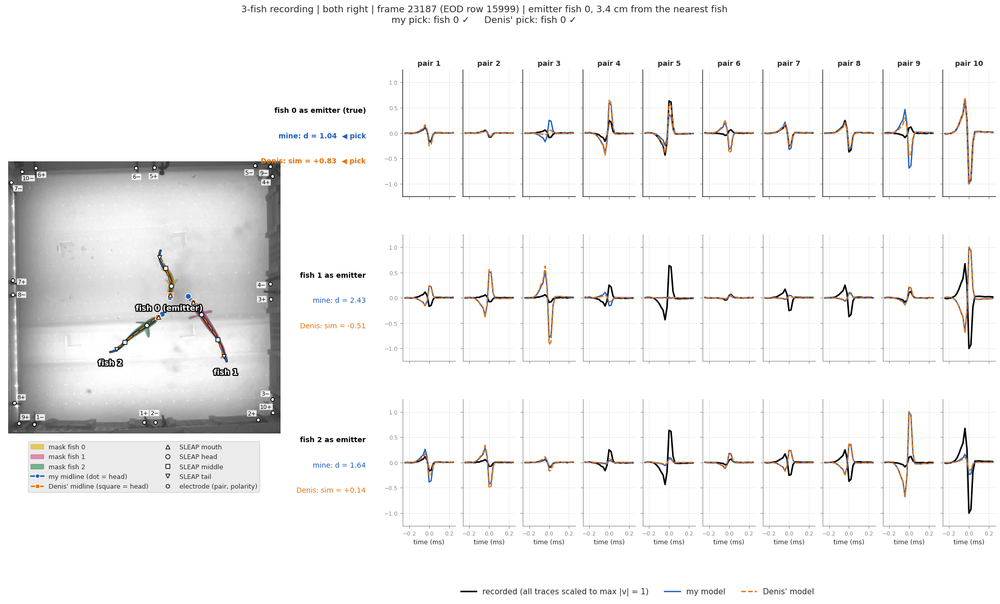

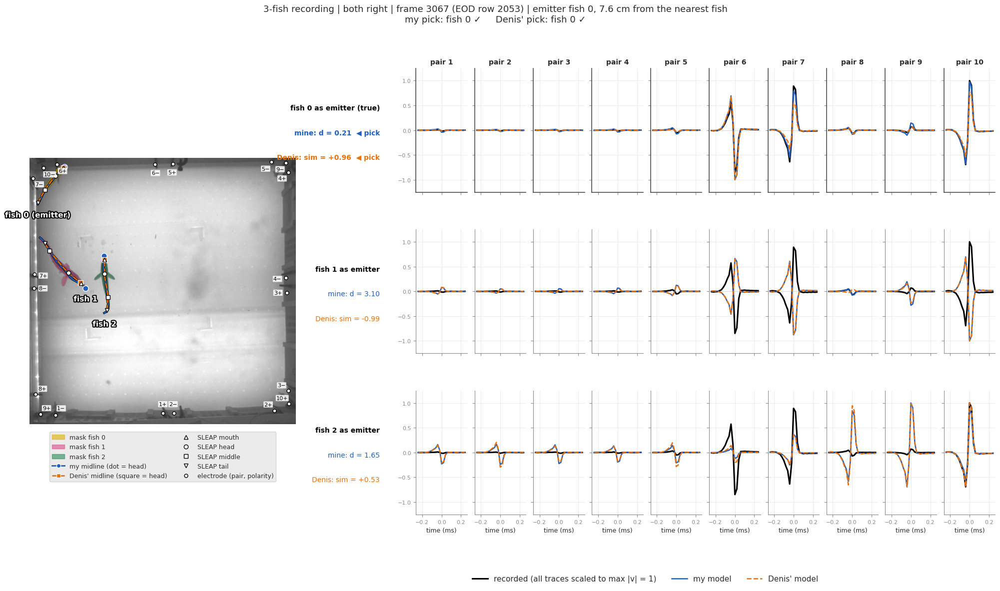

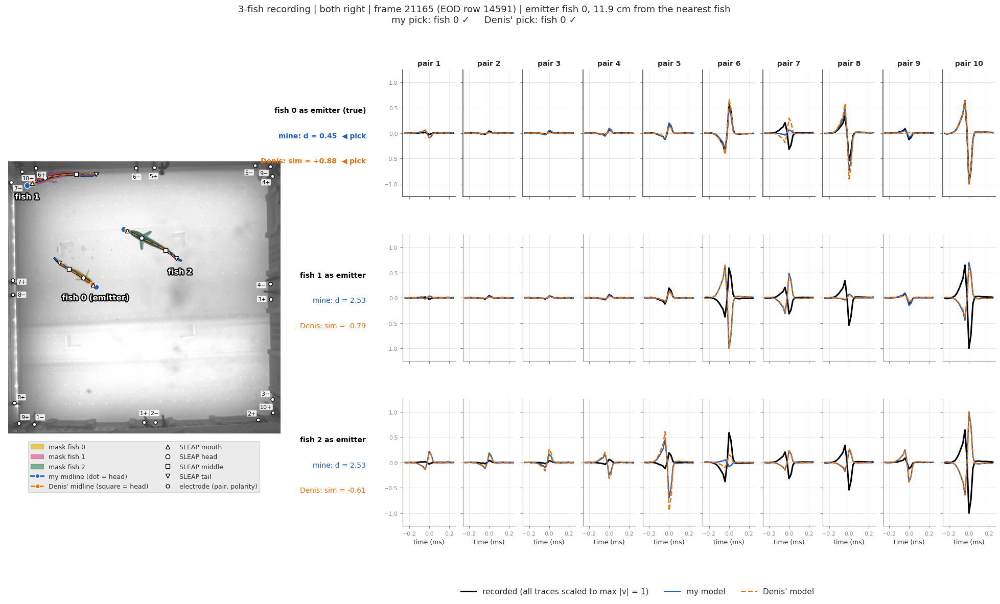

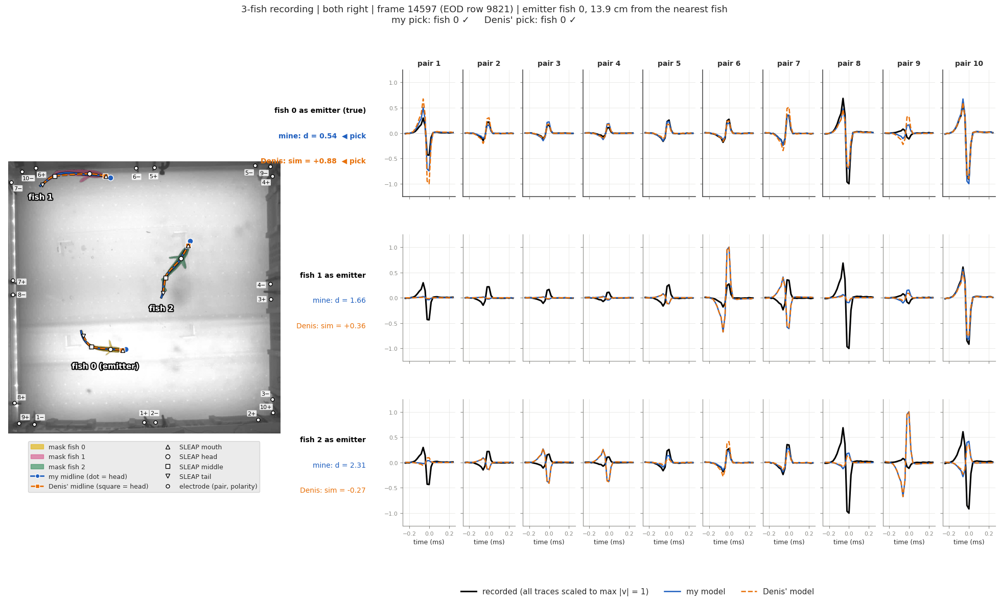

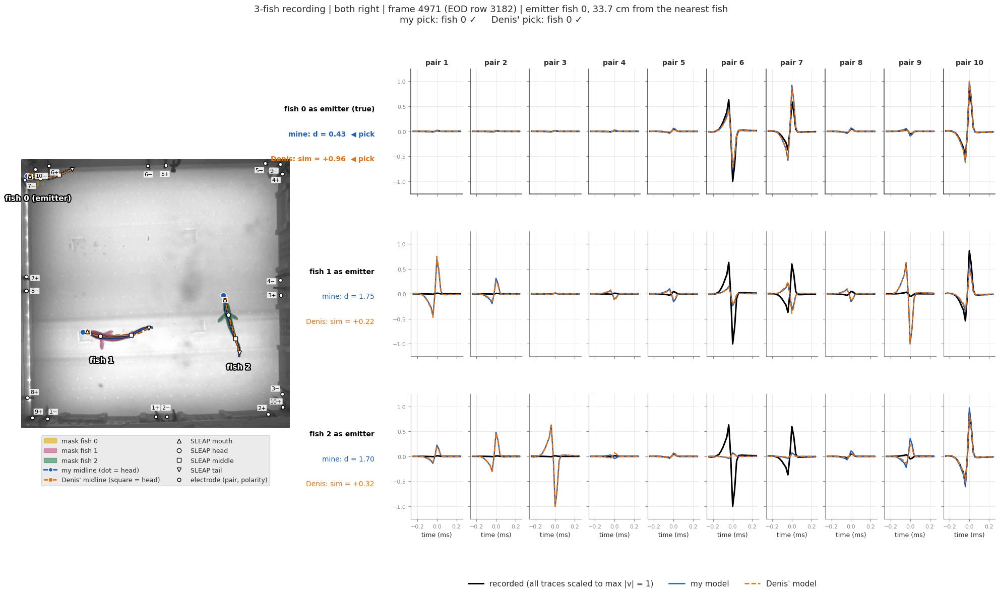

...

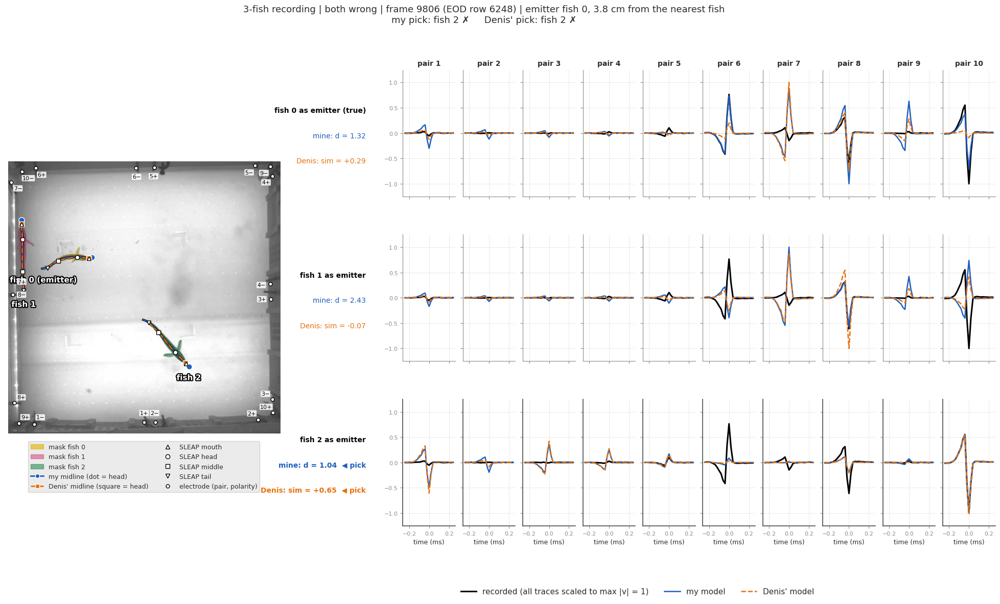

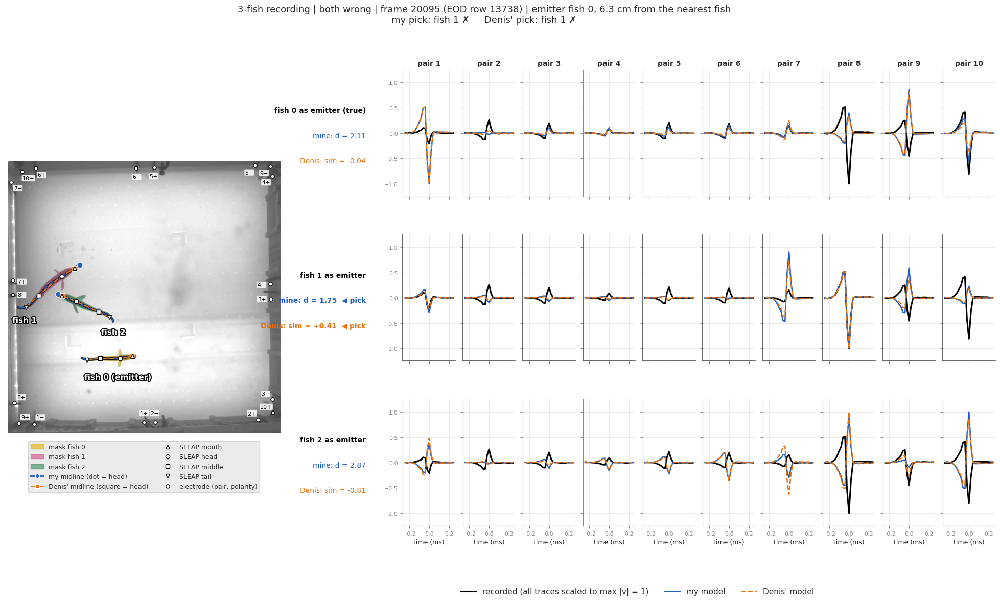

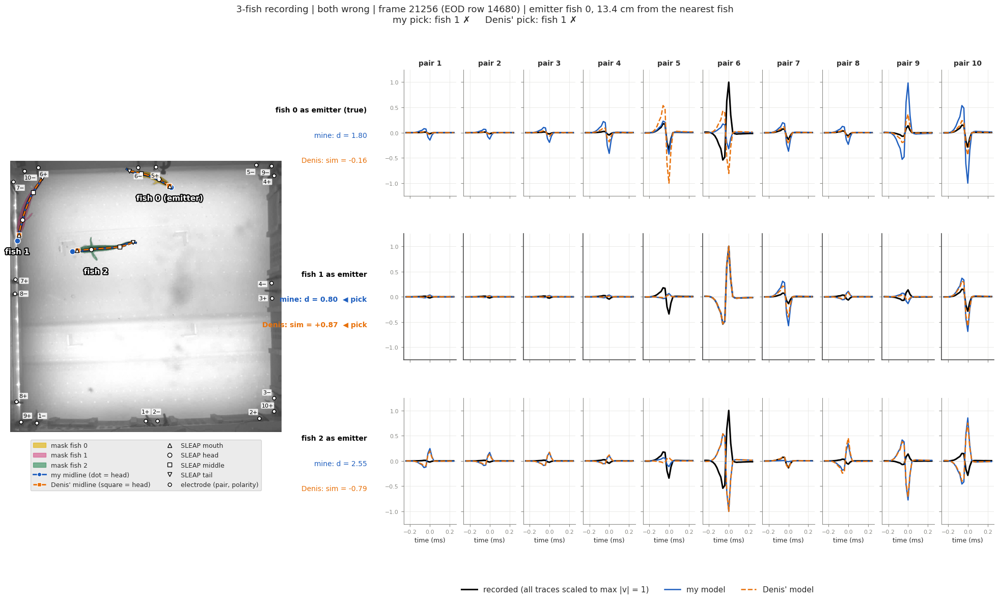

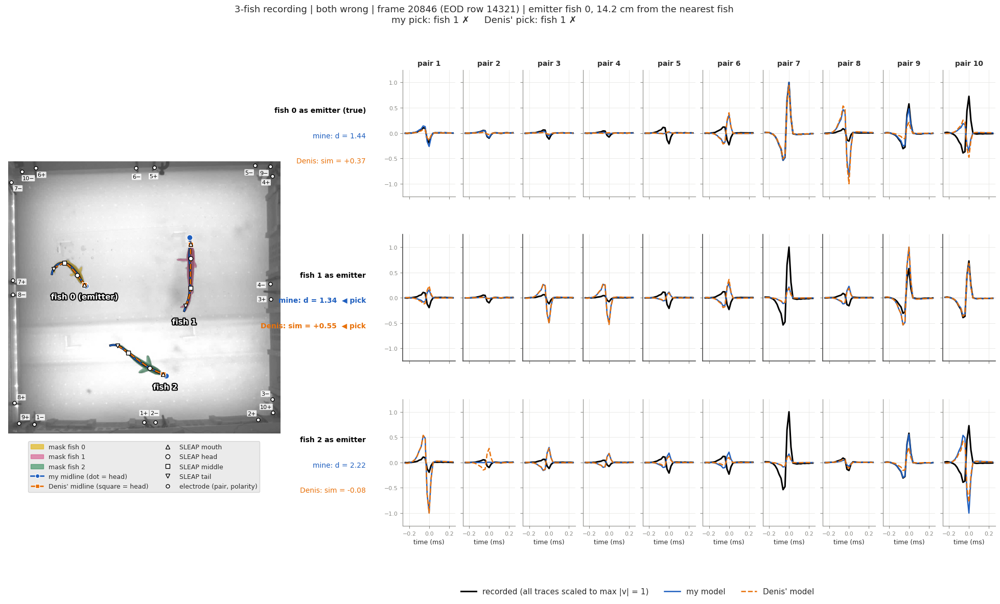

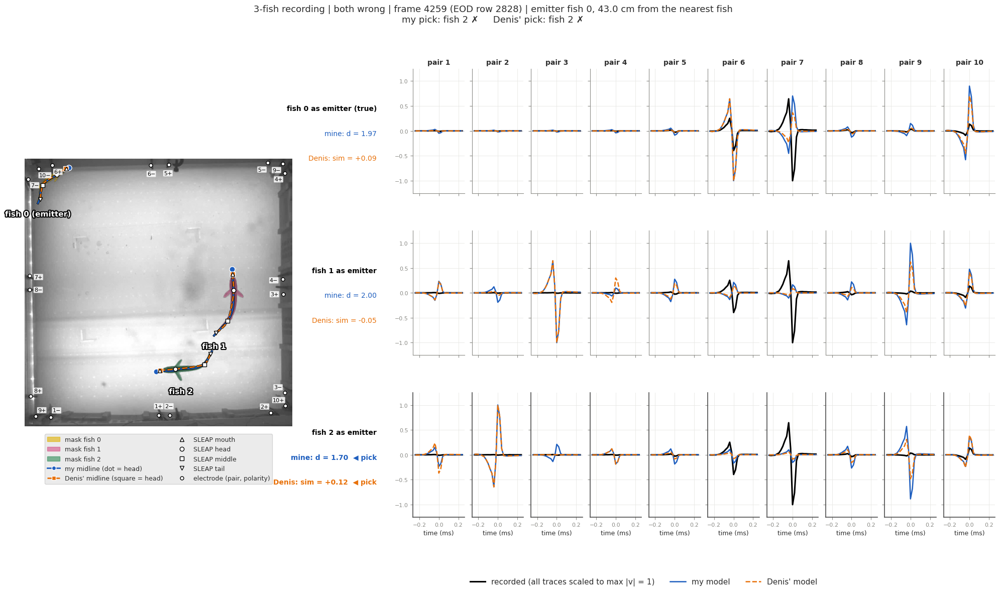

In [5]:
ex3 = run_recording('3-fish')

## 2-fish recording (emitter fish 1, the larger; fish 0 is silent)

Figures saved in `results/eod_ground_truth/conductivities/examples_mine_vs_denis/`.

only Denis right: no usable EOD in distance fifth 2, took one at 47.2 cm (fifth median 35.7 cm)
2-fish: 3532 good-frame EODs; distance fifths (cm): 0.5, 10.4, 28.6, 37.0, 46.7, 62.3
distance fifth      0    1    2    3    4
outcome                                  
both right        639  680  685  684  670
only mine right    20    5    8    9   13
only Denis right   20    2    0    1    5
both wrong         28   19   13   12   19


,frame,outcome,distance fifth,emitter to nearest fish (cm),my pick,Denis' pick
row,,,,,,
2548,4732,both right,0,7.83,1,1
1175,1981,both right,1,11.67,1,1
15589,38270,both right,2,35.72,1,1
10473,23828,both right,3,41.21,1,1
3327,6880,both right,4,48.00,1,1
2049,3726,only mine right,0,0.79,1,0
1472,2579,only mine right,1,15.07,1,0
17342,43779,only mine right,2,28.76,1,0
14616,34491,only mine right,3,46.68,1,0


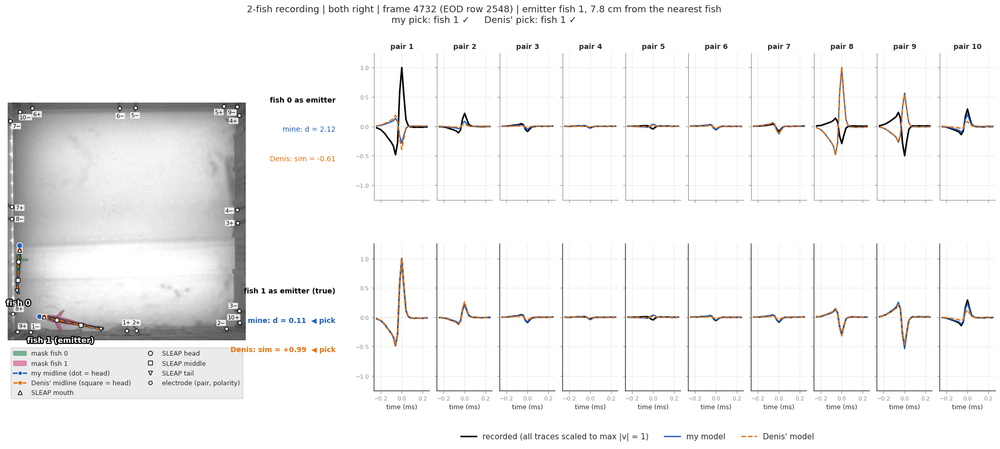

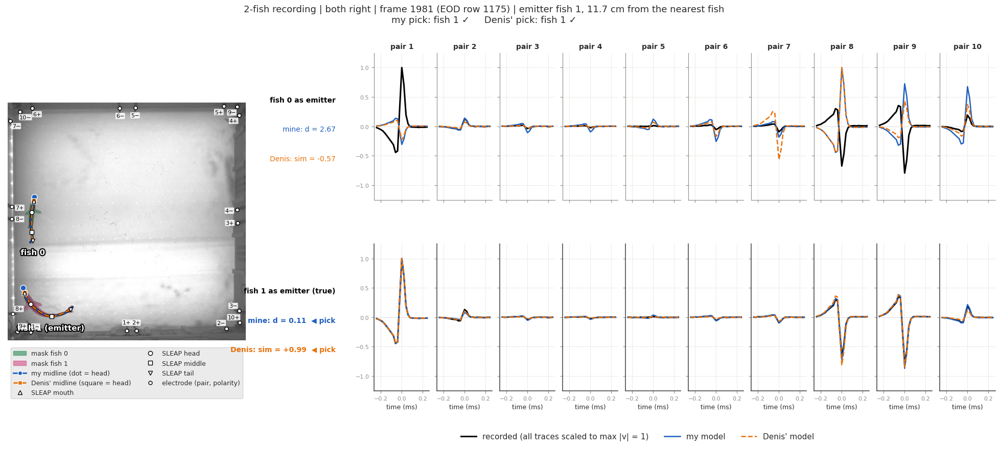

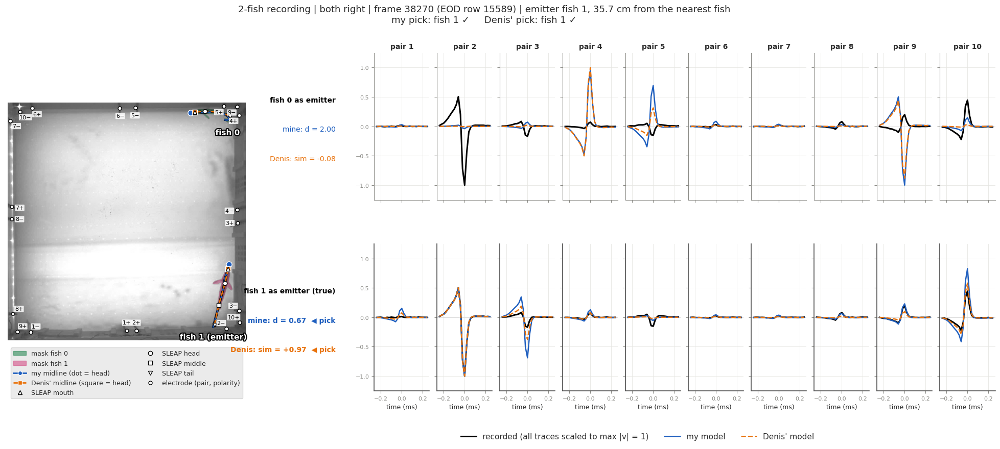

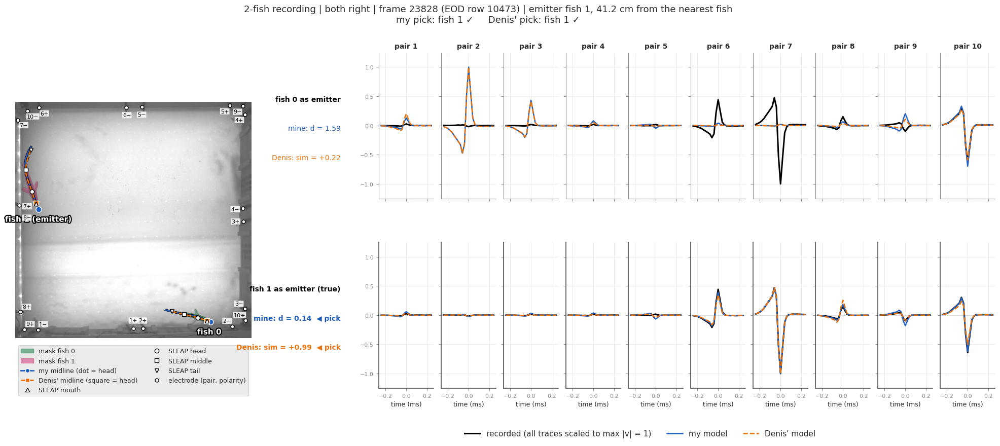

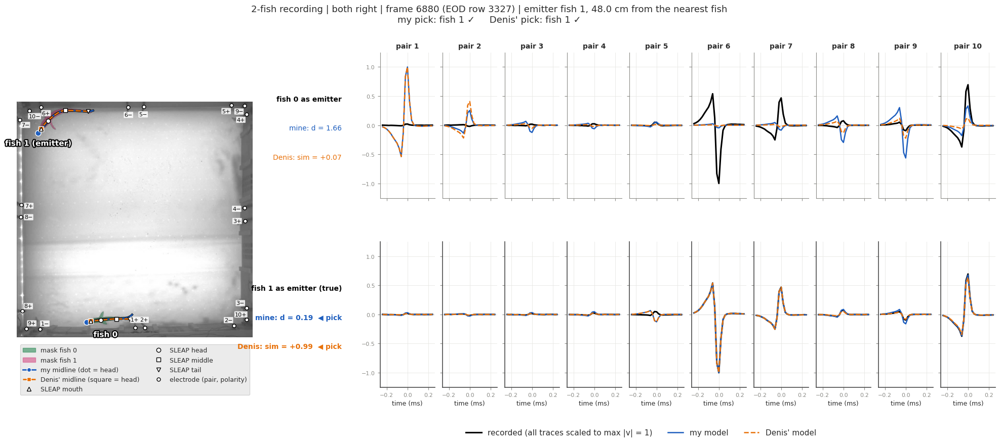

...

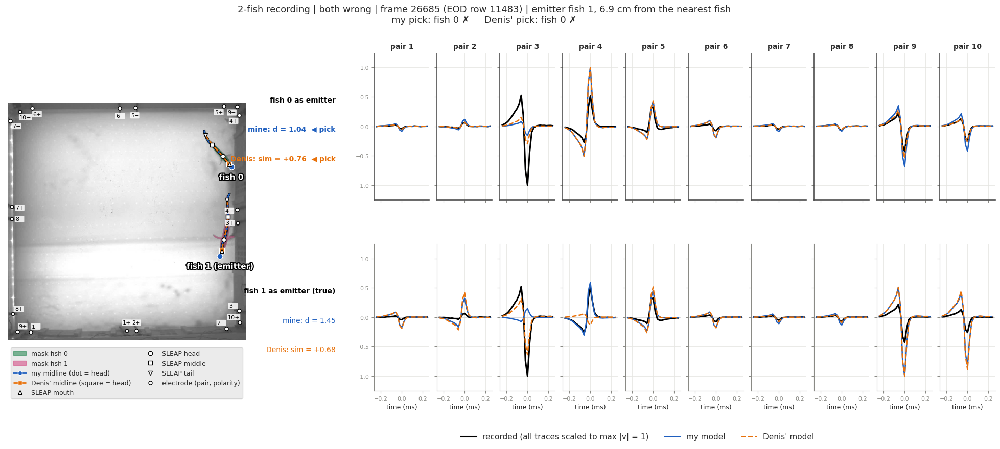

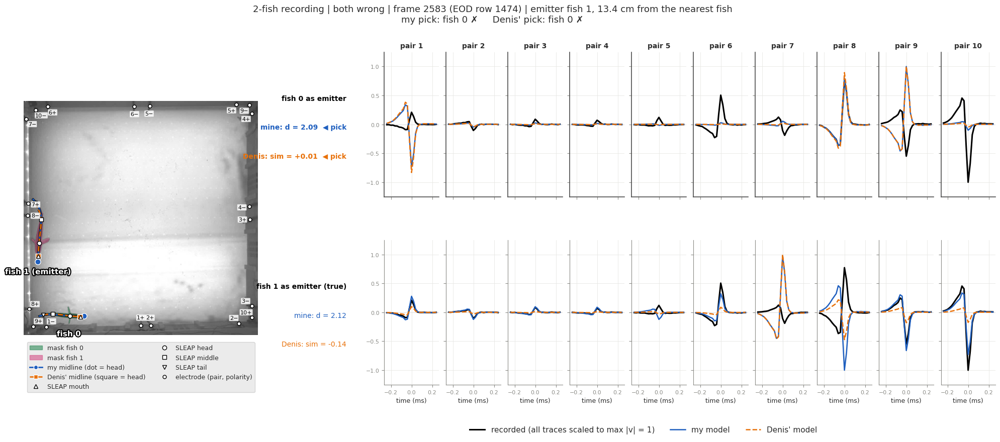

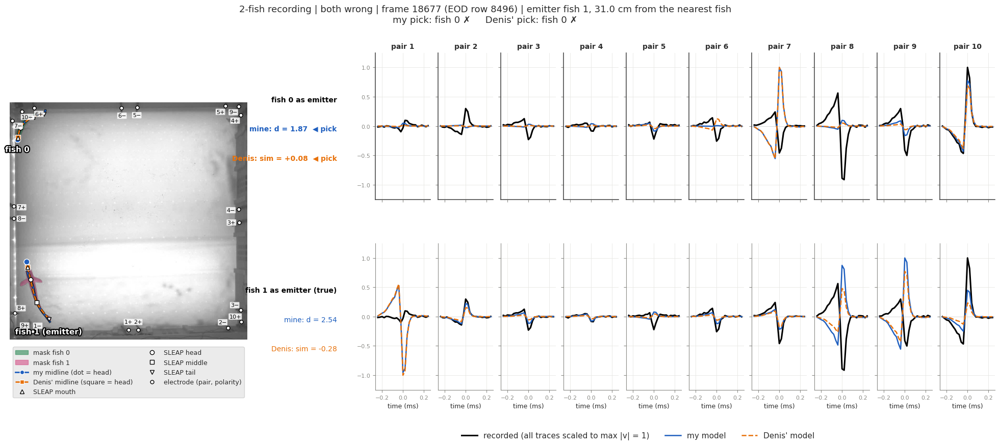

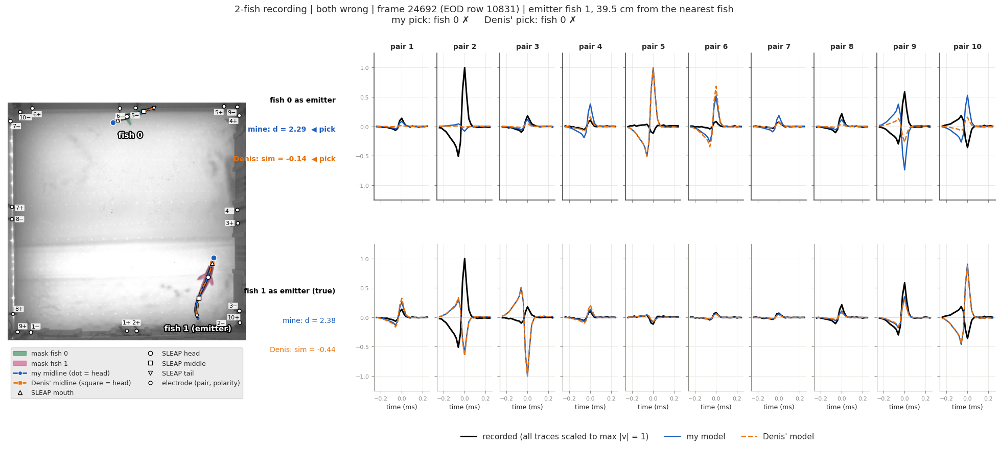

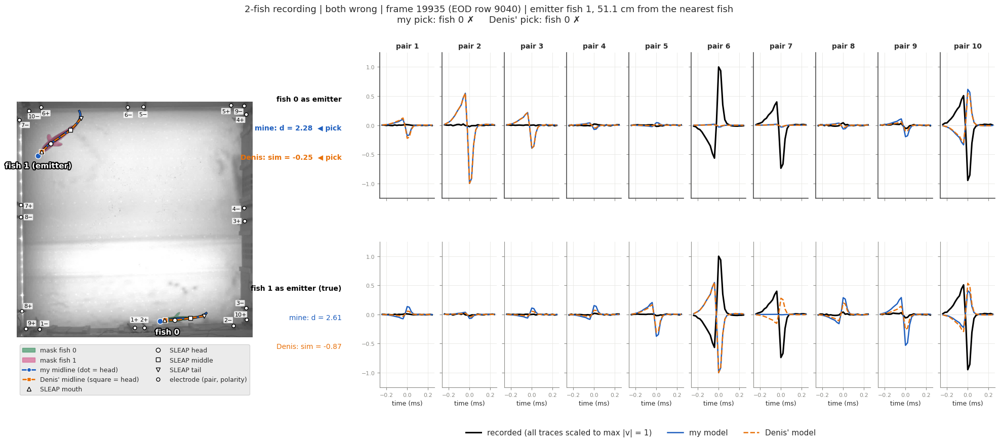

In [6]:
ex2 = run_recording('2-fish')